# Generative AI Applications - Conditional DCGAN on Fashion-MNIST

**Task:** train a small generative model that produces new `28x28` grayscale garment images, conditioned on one of the `10` Fashion-MNIST classes (Xiao et al., 2017, MIT license).

**Model:** a conditional deep convolutional GAN (Radford et al., 2016) with label conditioning (Mirza and Osindero, 2014), trained with two-sided label smoothing (an extension of the one-sided variant of Salimans et al., 2016).

**Held fixed:** `50` epochs, batch size `128`, Adam (`lr=2e-4`, betas `(0.5, 0.999)`), the evaluation-mode generation protocol, and one disclosed seed (`42`).

**Research question:** do the generated images match their requested class, and how close are they to real images in a trained classifier's feature space?

## How this notebook is organised

- Imports
- Task definition and model choice
- Dataset description, loading, and inspection
- Conditional DCGAN model
- Training
- Qualitative output evaluation (Figures 2–5)
- Quantitative evaluation (Figures 6–7), including the generation protocol and headline measurements
- Run instructions: environment and data
- Notebook summary

> The disclosed seed makes the run deterministic.

## Imports


In [1]:
# Import dependencies, set the disclosed seed (SEED=42), detect the device, and create figures/ for saved figures.
import hashlib
import math
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__}, CUDA available: {torch.cuda.is_available()}, device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

torch 2.11.0+cu128, CUDA available: True, device: cuda
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


## Task definition and model choice


### The task

A generative model learns the patterns of a training set and then produces new images from random noise. This notebook trains one on Fashion-MNIST.


### The model choice

The architecture follows Radford et al. (2016), with class conditioning based on Mirza and Osindero (2014).

The training process uses two-sided label smoothing. The discriminator receives `0.9` as the target for real images and `0.1` for generated images. This variant extends the one-sided label smoothing described by Salimans et al. (2016). It reduces the risk that the discriminator becomes overconfident.

### Why use a conditional model?

Fashion-MNIST contains `10` product categories. Conditioning the generator on a class label makes it possible to request a specific category. With the noise vector held fixed, the per-class grids show how the label changes the generated content.


### Evaluation approach

The qualitative evaluation examines the generated images and the figures below. The quantitative evaluation measures class agreement, feature-space Fréchet distance, and intra-class diversity. A separate evaluation classifier predicts the class of each generated image, following the class-conditional evaluation approach of Odena et al. (2017). All three quantitative measurements share the classifier's representation and its potential biases.


## Dataset: description, loading, and inspection


### The dataset

Fashion-MNIST, released by Zalando Research, contains `70,000` grayscale images, each with a resolution of `28x28` pixels. The dataset has `10` classes, with `7,000` images per class.

The images are product renderings derived from retailer photographs and distributed in IDX format. The `DATASET.md` file records the access policy, license, and archive checksums.

### Load Fashion-MNIST (offline-first) and print the split counts

Loading reads from the repository's `data/` directory first, with `download=True` only as a documented fallback. Image values are scaled to the range `[-1, 1]` to match the generator's `Tanh` output (Radford et al., 2016).


In [2]:
# Load the local dataset and print the per-class counts.
DATA_ROOT = Path("data")

tf = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ]
)

try:
    train_data = datasets.FashionMNIST(DATA_ROOT, train=True, download=False, transform=tf)
    test_data = datasets.FashionMNIST(DATA_ROOT, train=False, download=False, transform=tf)
except Exception as exc:
    print(f"Offline load failed ({exc}); falling back to download=True")
    train_data = datasets.FashionMNIST(DATA_ROOT, train=True, download=True, transform=tf)
    test_data = datasets.FashionMNIST(DATA_ROOT, train=False, download=True, transform=tf)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

labels = np.asarray(train_data.targets)
counts = np.bincount(labels, minlength=10)
print("training images:", len(train_data), "test images:", len(test_data))
for i, name in enumerate(CLASSES):
    print(f"  class {i} {name:<12} {counts[i]:5d} images")
assert counts.min() == counts.max(), "per-class count imbalance: " + str(counts)


training images: 60000 test images: 10000
  class 0 T-shirt/top   6000 images
  class 1 Trouser       6000 images
  class 2 Pullover      6000 images
  class 3 Dress         6000 images
  class 4 Coat          6000 images
  class 5 Sandal        6000 images
  class 6 Shirt         6000 images
  class 7 Sneaker       6000 images
  class 8 Bag           6000 images
  class 9 Ankle boot    6000 images


### Verify the documented checksums before any training


In [3]:
# Verify the checksums documented in DATASET.md before training.
# These hashes verify the provenance and integrity of the four compressed download archives.
# torchvision uses the extracted IDX files. The notebook does not hash these extracted files again.

# Expected SHA256 values and file sizes from DATASET.md.
DATASET_SHA256 = {
    "train-images-idx3-ubyte.gz": "3aede38d61863908ad78613f6a32ed271626dd12800ba2636569512369268a84",
    "train-labels-idx1-ubyte.gz": "a04f17134ac03560a47e3764e11b92fc97de4d1bfaf8ba1a3aa29af54cc90845",
    "t10k-images-idx3-ubyte.gz": "346e55b948d973a97e58d2351dde16a484bd415d4595297633bb08f03db6a073",
    "t10k-labels-idx1-ubyte.gz": "67da17c76eaffca5446c3361aaab5c3cd6d1c2608764d35dfb1850b086bf8dd5",
}

DATASET_SIZES = {
    "train-images-idx3-ubyte.gz": 26421880,
    "train-labels-idx1-ubyte.gz": 29515,
    "t10k-images-idx3-ubyte.gz": 4422102,
    "t10k-labels-idx1-ubyte.gz": 5148,
}

raw_dir = DATA_ROOT / "FashionMNIST" / "raw"
for name, expected_hash in DATASET_SHA256.items():
    archive = raw_dir / name
    digest = hashlib.sha256(archive.read_bytes()).hexdigest()
    assert digest == expected_hash, f"SHA256 mismatch for {name}: {digest}"
    assert archive.stat().st_size == DATASET_SIZES[name], f"size mismatch for {name}"
print(f"dataset integrity: {len(DATASET_SHA256)}/4 archives match DATASET.md (SHA256 + size)")


dataset integrity: 4/4 archives match DATASET.md (SHA256 + size)


### Real reference samples, one per class (Figure 1)


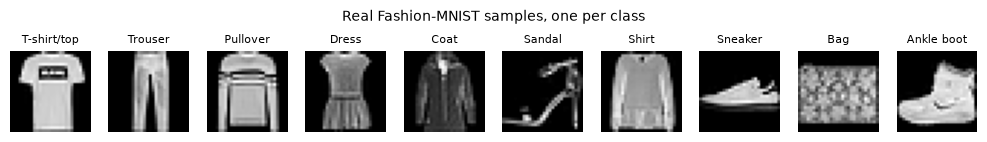

In [4]:
# Select one real reference sample per class, in training-set order.
# Reuse these real rows in the real-vs-generated comparison.

shown = torch.full((10,), -1, dtype=torch.long)
real_by_class = torch.zeros(10, 1, 28, 28)
idx = 0
for im, lab in train_data:
    if shown[lab] == -1:
        shown[lab] = idx
        real_by_class[lab] = im
        if int(shown.min()) >= 0:
            break
    idx += 1

fig = plt.figure(figsize=(10, 1.4))
for i in range(10):
    ax = fig.add_subplot(1, 10, i + 1)
    ax.imshow((real_by_class[i, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASSES[i], fontsize=8)
    ax.axis("off")
fig.suptitle("Real Fashion-MNIST samples, one per class", fontsize=10)
fig.tight_layout()
fig.savefig(FIGDIR / "fig0-real-samples.png", bbox_inches="tight", dpi=110)
plt.show()


## Model: conditional DCGAN

The generator takes a `100`-dimensional noise vector and a class label and produces a `28x28` image. The discriminator receives the image together with the label, reshaped as an additional `28x28` input channel, and scores the pair.

BatchNorm placement and the activation choices follow the DCGAN guidelines (Radford et al., 2016).


### Define the generator and discriminator, then verify tensor shapes


In [5]:

# Define the generator and discriminator for the conditional Fashion-MNIST GAN.
NZ = 100          # noise dimension
N_CLASSES = 10
EMB = 16          # label embedding dimension
G_BASE = 256      # generator base channels


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_embedding = nn.Embedding(N_CLASSES, EMB)
        self.fc = nn.Linear(NZ + EMB, 7 * 7 * G_BASE)
        self.net = nn.Sequential(
            nn.BatchNorm1d(7 * 7 * G_BASE),
            nn.ReLU(True),
            nn.Unflatten(1, (G_BASE, 7, 7)),
            nn.ConvTranspose2d(G_BASE, 128, kernel_size=4, stride=2, padding=1),  # 7x7 -> 14x14
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),      # 14x14 -> 28x28
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, kernel_size=3, stride=1, padding=1),        # 28x28
            nn.Tanh(),
        )

    def forward(self, z, labels):
        y = self.label_embedding(labels)
        return self.net(self.fc(torch.cat([z, y], dim=1)))


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_map = nn.Embedding(N_CLASSES, 28 * 28)   # label rendered as an image channel
        self.features = nn.Sequential(
            nn.Conv2d(2, 64, kernel_size=4, stride=2, padding=1),   # 28x28 -> 14x14 (image + label map)
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 14x14 -> 7x7
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, True),
            nn.Flatten(),
        )
        self.head = nn.Linear(128 * 7 * 7, 1)  # the explicit dense output head

    def forward(self, imgs, labels):
        ymap = self.label_map(labels).view(-1, 1, 28, 28)
        return self.head(self.features(torch.cat([imgs, ymap], dim=1)))


G = Generator().to(DEVICE)
D = Discriminator().to(DEVICE)

# Verify the tensor shapes produced by the generator (G) and discriminator (D).
# Use eval mode so the diagnostic forward passes do not change the BatchNorm running statistics.
G.eval()
D.eval()
z_probe = torch.randn(4, NZ, device=DEVICE)
y_probe = torch.randint(0, N_CLASSES, (4,), device=DEVICE)
img_probe = torch.randn(4, 1, 28, 28, device=DEVICE)
with torch.no_grad():
    g_out = G(z_probe, y_probe)
    d_out = D(img_probe, y_probe)
G.train()
D.train()
assert g_out.shape == (4, 1, 28, 28), g_out.shape
assert d_out.shape == (4, 1), d_out.shape
print("G(z, y) ->", tuple(g_out.shape), "D(img, y) ->", tuple(d_out.shape))
n_g = sum(p.numel() for p in G.parameters())
n_d = sum(p.numel() for p in D.parameters())
print(f"trainable parameters: generator {n_g:,}, discriminator {n_d:,}")


G(z, y) -> (4, 1, 28, 28) D(img, y) -> (4, 1)
trainable parameters: generator 2,149,409, discriminator 147,681


## Training

Training uses the standard two-step update with Adam and `BCEWithLogitsLoss` applied to raw logits (Radford et al., 2016). The targets use the two-sided label smoothing described with the model choice. The generator still trains against the hard real target.

The discriminator baseline is approximately `2*ln(2) = 1.386`, the sum of two binary terms, and the generator baseline is approximately `ln(2) = 0.693`. Figure 2 shows both baselines. The run also records the networks' mean logits.


### Train 50 epochs with label smoothing, recording losses and fixed-noise snapshots


In [6]:
# Training configuration and loop for conditional GAN on Fashion-MNIST
EPOCHS = 50
BATCH_SIZE = 128
LR = 2e-4
REAL_TARGET = 0.9   # label smoothing (a two-sided variant of Salimans et al., 2016)
FAKE_TARGET = 0.1
D_CHANCE = 2 * math.log(2)   # ~1.386, sum of two BCE terms
G_CHANCE = math.log(2)       # ~0.693, one BCE term

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
criterion = nn.BCEWithLogitsLoss()
optG = optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optD = optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

# Fixed evaluation inputs (drawn from the setup cell's seeding; a full notebook run reproduces them)
n_snap = 64  # batch of 64 keeps train-mode BatchNorm statistics representative
fixed_z = torch.randn(n_snap, NZ, device=DEVICE)
fixed_labels = torch.arange(n_snap, device=DEVICE) % N_CLASSES  # 0..9 cycling
SNAP_EPOCHS = {1, 5, 10, 25, 50}
snapshots = {}

d_losses, g_losses, d_logits_real_m, d_logits_fake_m = [], [], [], []

start = time.time()
for epoch in range(1, EPOCHS + 1):
    ep_d, ep_g = [], []
    for imgs, labels in train_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        bs = imgs.size(0)

        # 1. Discriminator: real toward REAL_TARGET, fake toward FAKE_TARGET
        optD.zero_grad()
        d_real = D(imgs, labels)
        d_logits_real_m.append(float(d_real.mean().detach()))
        loss_real = criterion(d_real, torch.full((bs, 1), REAL_TARGET, device=DEVICE))
        fake_z = torch.randn(bs, NZ, device=DEVICE)
        with torch.no_grad():
            fake_imgs = G(fake_z, labels)
        d_fake = D(fake_imgs, labels)
        d_logits_fake_m.append(float(d_fake.mean().detach()))
        loss_fake = criterion(d_fake, torch.full((bs, 1), FAKE_TARGET, device=DEVICE))
        d_loss = loss_real + loss_fake
        d_loss.backward()
        optD.step()

        # 2. Generator: fakes judged against hard real targets
        optG.zero_grad()
        g_z = torch.randn(bs, NZ, device=DEVICE)
        g_logits = D(G(g_z, labels), labels)
        g_loss = criterion(g_logits, torch.ones(bs, 1, device=DEVICE))
        g_loss.backward()
        optG.step()

        ep_d.append(float(d_loss.detach()))
        ep_g.append(float(g_loss.detach()))

    d_losses.append(float(np.mean(ep_d)))
    g_losses.append(float(np.mean(ep_g)))
    if epoch in SNAP_EPOCHS:
        # Diagnostics must not perturb training: eval mode uses the running
        # statistics as they are (train mode would update them again here)
        G.eval()
        with torch.no_grad():
            snapshots[epoch] = G(fixed_z, fixed_labels).detach().cpu()
        G.train()
    print(f"epoch {epoch:2d}  D {d_losses[-1]:.3f}  G {g_losses[-1]:.3f}")

elapsed = time.time() - start
print(f"total training time: {elapsed:.1f} s ({elapsed / 60:.1f} min), {elapsed / EPOCHS:.1f} s/epoch")


epoch  1  D 0.814  G 2.019


epoch  2  D 1.103  G 1.217


epoch  3  D 1.074  G 1.206


epoch  4  D 1.132  G 1.140


epoch  5  D 1.202  G 1.026


epoch  6  D 1.240  G 0.966


... (40 outputs left out)

epoch 47  D 1.389  G 0.723


epoch 48  D 1.390  G 0.723


epoch 49  D 1.390  G 0.723


epoch 50  D 1.390  G 0.723
total training time: 443.9 s (7.4 min), 8.9 s/epoch


## Output evaluation (qualitative)

This section presents four figures. The run also saves each figure as a PNG in `figures/`.

### Generation protocol

All generation uses evaluation mode. Its BatchNorm layers use the running statistics collected during training. An image's output does not depend on the other images in its batch. The quantitative evaluation below tests this property directly.


### Training losses against chance baselines (Figure 2)


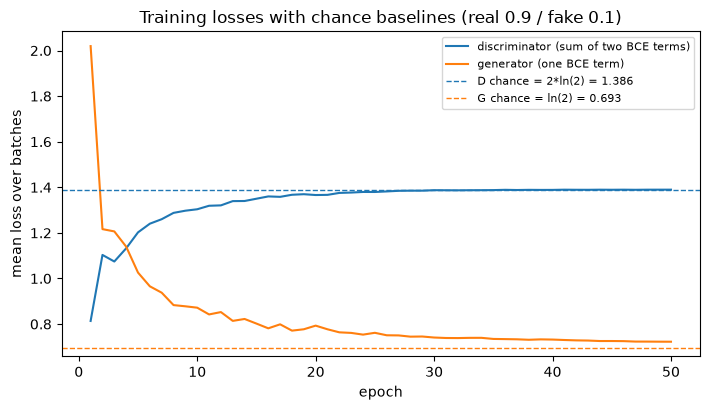

final epoch: D loss 1.390 (chance 1.386), G loss 0.723 (chance 0.693)
epoch 1:     D loss 0.814, G loss 2.019
mean D(real logits) 0.133, mean D(fake logits) -0.134


In [7]:
# Loss curves for both networks against their chance baselines
fig, ax = plt.subplots(figsize=(7.2, 4.2))
xs = np.arange(1, EPOCHS + 1)
ax.plot(xs, d_losses, label="discriminator (sum of two BCE terms)")
ax.plot(xs, g_losses, label="generator (one BCE term)")
ax.axhline(D_CHANCE, color="tab:blue", linestyle="--", linewidth=1, label=f"D chance = 2*ln(2) = {D_CHANCE:.3f}")
ax.axhline(G_CHANCE, color="tab:orange", linestyle="--", linewidth=1, label=f"G chance = ln(2) = {G_CHANCE:.3f}")
ax.set_xlabel("epoch")
ax.set_ylabel("mean loss over batches")
ax.set_title("Training losses with chance baselines (real 0.9 / fake 0.1)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "fig1-loss-curves.png", dpi=110)
plt.show()
print(f"final epoch: D loss {d_losses[-1]:.3f} (chance {D_CHANCE:.3f}), G loss {g_losses[-1]:.3f} (chance {G_CHANCE:.3f})")
print(f"epoch 1:     D loss {d_losses[0]:.3f}, G loss {g_losses[0]:.3f}")
print(f"mean D(real logits) {np.mean(d_logits_real_m):.3f}, mean D(fake logits) {np.mean(d_logits_fake_m):.3f}")

**Loss curves (Figure 2).** The run ends close to the stated chance baselines. The final discriminator loss is `1.390`, within `0.004` of its `1.386` baseline. The final generator loss is `0.723`, compared with its `0.693` baseline.

Both curves remain flat during the second half of training. The figure shows no divergence or collapse. However, loss values alone cannot establish that the adversarial game has converged or that the generated and real distributions are equivalent.

### Sample progression across snapshot epochs (Figure 3)


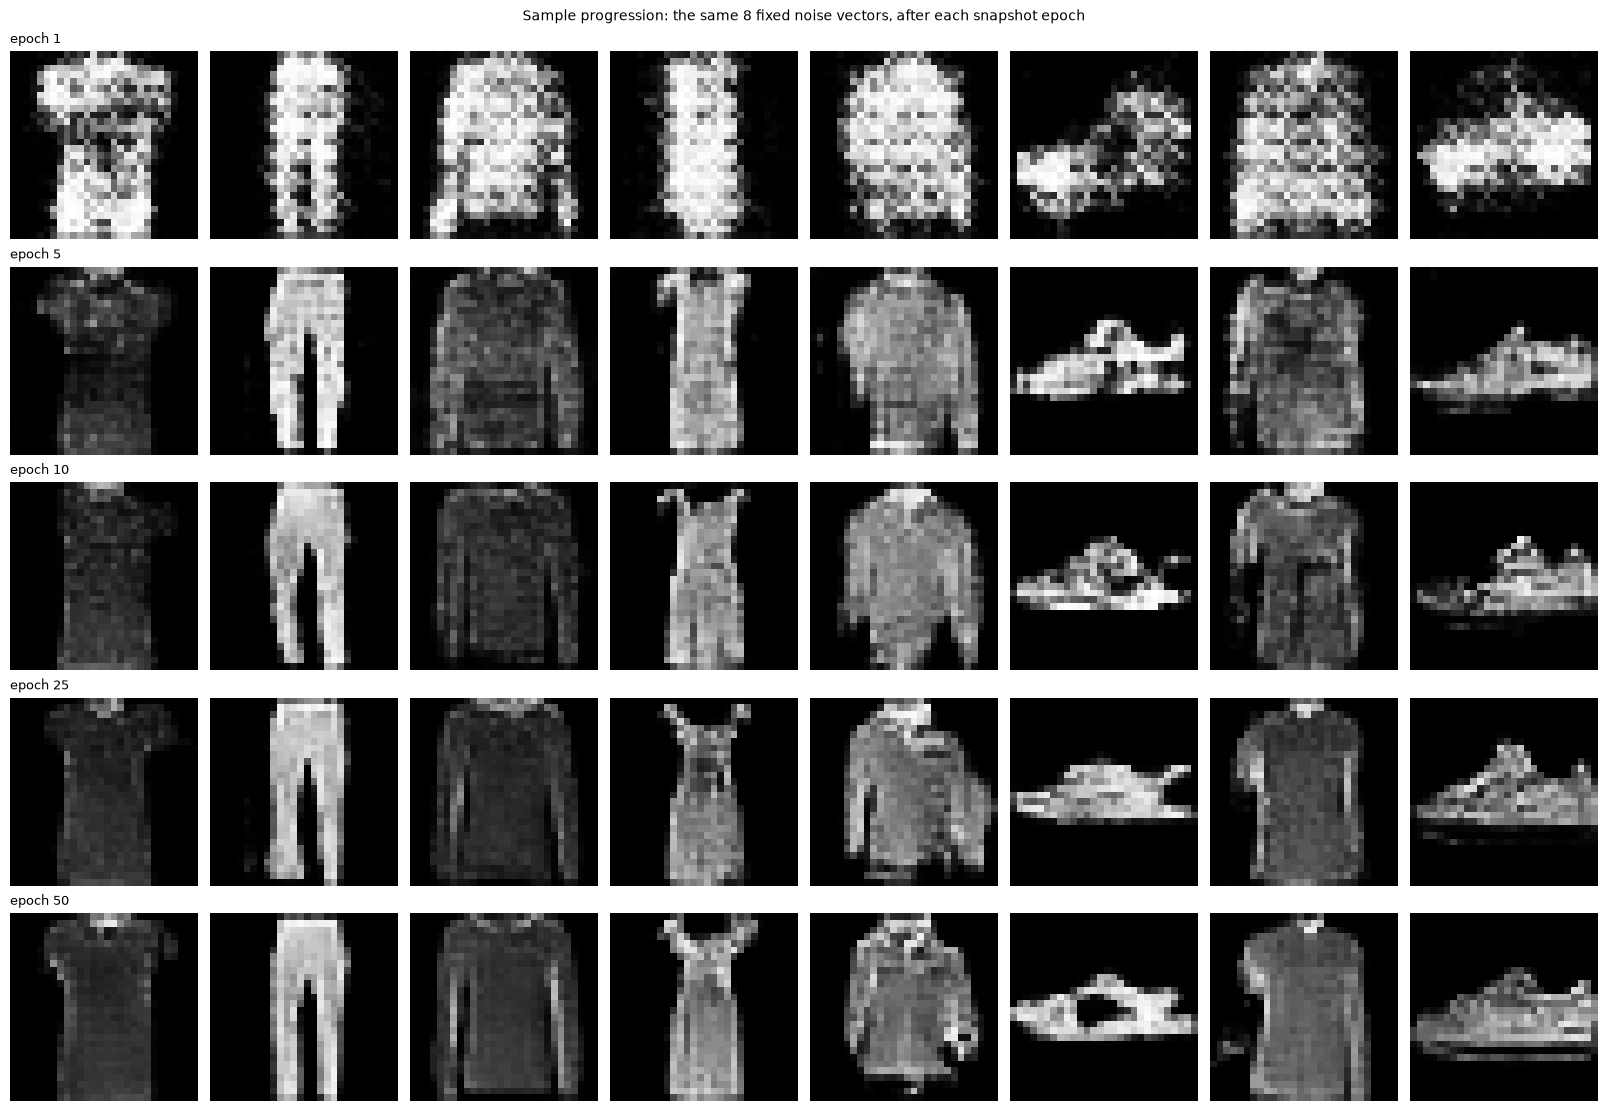

In [8]:
# The same fixed noise batch rendered as tiles per snapshot epoch
rows = sorted(snapshots)
fig = plt.figure(figsize=(2 * 8, 2.2 * len(rows)), layout="constrained")
for r, ep in enumerate(rows):
    tiles = snapshots[ep][:8]  # first 8 fixed-noise samples
    for c in range(8):
        ax = fig.add_subplot(len(rows), 8, r * 8 + c + 1)
        ax.imshow((tiles[c, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if c == 0:
            ax.set_title(f"epoch {ep}", loc="left", fontsize=9)
fig.suptitle("Sample progression: the same 8 fixed noise vectors, after each snapshot epoch", fontsize=10)
fig.savefig(FIGDIR / "fig2-progression.png", dpi=110, bbox_inches="tight")
plt.show()

**Sample progression (Figure 3).** The figure shows the same eight fixed noise-and-label pairs at each snapshot epoch. At epoch `1`, the images contain faint outlines. By epoch `5`, trousers and a sandal silhouette are recognizable. The snapshots at epochs `10`, `25`, and `50` show further detail without changing the identity of the tiles.

The run remains stable during the second half of training, consistent with the flat loss curves in Figure 1.

### Class-conditioned grids: fixed noise, swept label (Figure 4)


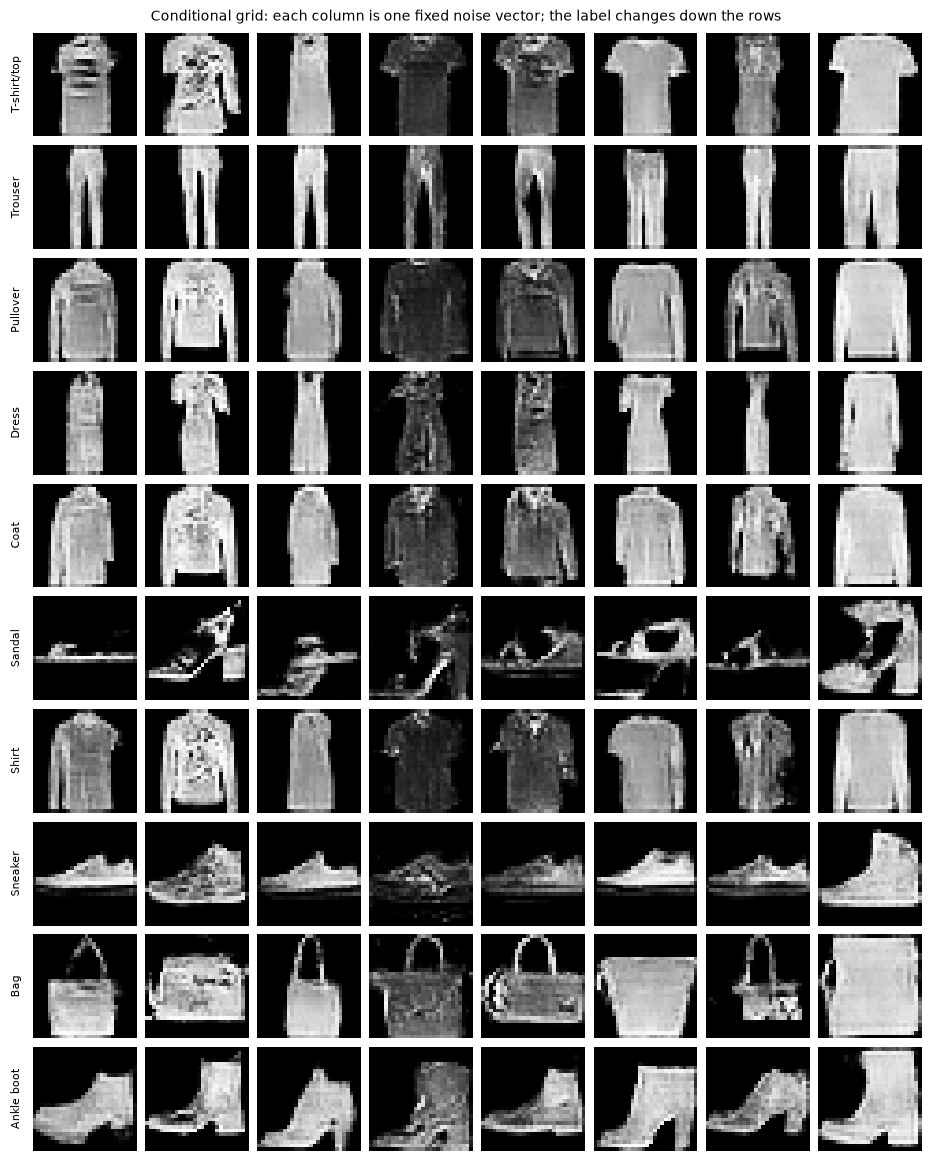

In [9]:
# Class-conditioned grid: one fixed noise vector per column, the label swept over rows with the noise held fixed
# Visualize how the generator responds to different class labels while keeping the noise vector fixed
G.eval()
n_per_class = 8
col_z = torch.randn(n_per_class, NZ, device=DEVICE)
rows = torch.arange(10, device=DEVICE)[:, None].expand(10, n_per_class)
zs = col_z[None].expand(10, n_per_class, NZ).reshape(-1, NZ)
ys = rows.reshape(-1)
with torch.no_grad():
    class_grid = G(zs, ys).reshape(10, n_per_class, 1, 28, 28).cpu()

fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.15, 10 * 1.15), layout="constrained")
for i in range(10):
    for j in range(n_per_class):
        ax = axes[i, j]
        ax.imshow((class_grid[i, j, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        if j == 0:
            ax.set_ylabel(CLASSES[i], fontsize=8, rotation=90, labelpad=8)
fig.suptitle("Conditional grid: each column is one fixed noise vector; the label changes down the rows", fontsize=10)
fig.savefig(FIGDIR / "fig3-conditional-grid.png", dpi=110, bbox_inches="tight")
plt.show()


**Class conditioning (Figure 4).** This grid shows the first generation pass after training. Each row corresponds to a class label. The Trouser row contains trousers, the Bag row contains bags with handles, the Sandal row contains heel sandals, and the Sneaker row contains low sneakers.

The quantitative evaluation below tests and adopts this generation protocol.

### Real vs generated matched pairs (Figure 5)


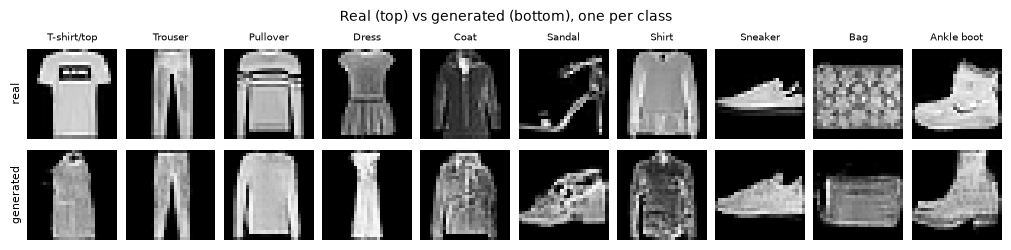

In [10]:
# Compare one real and one generated image per class.
# Place the real image above the generated image. Use the same class label and a fixed noise batch in eval mode.
G.eval()
with torch.no_grad():
    gen_pairs = G(torch.randn(10, NZ, device=DEVICE), torch.arange(10, device=DEVICE)).cpu()
fig, axes = plt.subplots(2, 10, figsize=(10, 2.4), layout="constrained")
for i in range(10):
    axes[0, i].imshow((real_by_class[i, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(CLASSES[i], fontsize=7)
    axes[1, i].imshow((gen_pairs[i, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
for row in axes:
    for ax in row:
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
axes[0, 0].set_ylabel("real", fontsize=8)
axes[1, 0].set_ylabel("generated", fontsize=8)
fig.suptitle("Real (top) vs generated (bottom), one per class", fontsize=10)
fig.savefig(FIGDIR / "fig4-real-vs-generated.png", dpi=110, bbox_inches="tight")
plt.show()


**Real and generated pairs (Figure 5).** Each pair contains one real image and one generated image from the same class. The real image appears above the generated image.

The silhouettes show similar class features, such as two trouser legs, a heel under the sandal, and a boot shaft. However, the generated images have more visible grain. Their grayscale tones appear flatter than those of the real images. The generated bag also lacks much of the woven pattern visible in the real example.

## Quantitative evaluation: class agreement, diversity, and the generation protocol

This section measures the generated images with the separate classifier described in the evaluation approach. Class agreement is the percentage of generated images for which the classifier predicts the conditioning label. The distance and diversity measurements use the classifier's `128`-dimensional features, following the feature-space approach of Heusel et al. (2017), and a real-vs-real comparison provides the reference value.

The classifier trains for `10` epochs, monitored on a held-out `10,000`-image validation split. The test split is read exactly once, after training. The evaluation uses `1,000` generated images per class.


### The evaluation classifier: a separate model trained only on real images


### Split the training pool: classifier-train and validation

The classifier trains on a stratified `50,000`-image pool carved from the real training split: `5,000` images per class. The remaining `1,000` images per class form a held-out validation split of `10,000` images.

The split uses the disclosed seed.


In [11]:
# Stratified split of the real training pool: 5,000 images per class train the
# classifier, 1,000 per class are held out for per-epoch validation.
gen_split = torch.Generator().manual_seed(SEED)
targets = train_data.targets if isinstance(train_data.targets, torch.Tensor) else torch.tensor(train_data.targets)
tr_parts, va_parts = [], []
for c in range(N_CLASSES):
    idx_c = (targets == c).nonzero(as_tuple=True)[0]
    perm = idx_c[torch.randperm(len(idx_c), generator=gen_split)]
    tr_parts.append(perm[:5000])
    va_parts.append(perm[5000:])
clf_train_idx = torch.cat(tr_parts)
val_idx = torch.cat(va_parts)
clf_train = torch.utils.data.Subset(train_data, clf_train_idx.tolist())
val_data = torch.utils.data.Subset(train_data, val_idx.tolist())
val_loader = DataLoader(val_data, batch_size=512, num_workers=0)
print(f"classifier training pool: {len(clf_train)} images (5,000 per class)")
print(f"validation split: {len(val_data)} images (1,000 per class), held out from classifier training")


classifier training pool: 50000 images (5,000 per class)
validation split: 10000 images (1,000 per class), held out from classifier training


In [12]:
# Define a separate classifier trained only on real images. It shares no parameters with the generator.
# Validation monitoring per epoch; the test split is evaluated once, after training.
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),
            nn.MaxPool2d(2),                                    # 28x28 -> 14x14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.MaxPool2d(2),                                    # 14x14 -> 7x7
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(True),
            nn.Linear(128, N_CLASSES),
        )

    def forward(self, x):
        return self.net(x)


EPOCHS_CLF = 10
BATCH_CLF = 128
torch.manual_seed(SEED)  # classifier training is deterministic like the GAN
criterion_clf = nn.CrossEntropyLoss()
clf = Classifier().to(DEVICE)
opt_clf = optim.Adam(clf.parameters(), lr=1e-3)
clf_loader = DataLoader(clf_train, batch_size=BATCH_CLF, shuffle=True, num_workers=0)
test_loader_clf = DataLoader(test_data, batch_size=512, num_workers=0)

n_clf = sum(p.numel() for p in clf.parameters())
print(f"classifier parameters: {n_clf:,}")

def validation_accuracy():
    clf.eval()
    correct, seen = 0, 0
    with torch.no_grad():
        for im, lab in val_loader:
            correct += int((clf(im.to(DEVICE)).argmax(1).cpu() == lab).sum())
            seen += lab.numel()
    return correct / seen

clf.train()
t_clf = time.time()
acc_per_epoch = []
for ep in range(1, EPOCHS_CLF + 1):
    clf.train()  # the accuracy check below leaves the module in eval mode
    run_loss, seen = 0.0, 0
    for im, lab in clf_loader:
        im, lab = im.to(DEVICE, non_blocking=True), lab.to(DEVICE, non_blocking=True)
        opt_clf.zero_grad()
        loss = criterion_clf(clf(im), lab)
        loss.backward()
        opt_clf.step()
        run_loss += float(loss.detach()) * im.size(0)
        seen += im.size(0)
    acc = validation_accuracy()
    acc_per_epoch.append(acc)
    print(f"classifier epoch {ep:2d}: train loss {run_loss / seen:.4f} | validation accuracy {acc:.4f}")
print(f"classifier training time {time.time() - t_clf:.0f} s over {EPOCHS_CLF} epochs")

# Evaluate the test split exactly once, after training: final accuracy plus the per-class confusion matrix
clf.eval()
confusion = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long)
with torch.no_grad():
    for im, lab in test_loader_clf:
        pred = clf(im.to(DEVICE)).argmax(1).cpu()
        for true_l, pred_l in zip(lab.tolist(), pred.tolist()):
            confusion[true_l, pred_l] += 1
test_acc = float(confusion.trace()) / confusion.sum().item()
real_per_class = [float(confusion[i, i]) / confusion[i].sum().item() for i in range(N_CLASSES)]
print(f"real test accuracy: {test_acc:.4f} (chance 0.10), evaluated once after training on {len(clf_train)} real train images")


classifier parameters: 421,834


classifier epoch  1: train loss 0.4069 | validation accuracy 0.9019


classifier epoch  2: train loss 0.2777 | validation accuracy 0.9054


classifier epoch  3: train loss 0.2330 | validation accuracy 0.9190


classifier epoch  4: train loss 0.2049 | validation accuracy 0.9214


classifier epoch  5: train loss 0.1825 | validation accuracy 0.9095


... (2 outputs left out)

classifier epoch  8: train loss 0.1261 | validation accuracy 0.9189


classifier epoch  9: train loss 0.1144 | validation accuracy 0.9209


classifier epoch 10: train loss 0.0976 | validation accuracy 0.9199
classifier training time 75 s over 10 epochs


real test accuracy: 0.9074 (chance 0.10), evaluated once after training on 50000 real train images


**Classifier training result.** The classifier's validation accuracy was `0.9019` after 1 epoch and `0.9199` after 10 epochs, between `0.917` and `0.925` during the last five epochs. The chance level is `0.10`.

The test split was evaluated once, after training. The classifier read `0.9074` of the `10,000` test images correctly.


### The generation protocol experiment: batch composition and running statistics


In [13]:
# Test six generation protocols (train/eval mode x mixed, single-class, and batch-size-one composition), 1,000 images each, noise seed SEED + 1.
# Train-mode BatchNorm updates its running statistics even inside no_grad, so the generator state is saved and restored around each pass.
torch.manual_seed(SEED + 1)
N_EVAL_PER_CLASS = 100
N_EVAL = N_CLASSES * N_EVAL_PER_CLASS
z_eval = torch.randn(N_EVAL, NZ, device=DEVICE)
y_eval = torch.arange(N_EVAL, device=DEVICE) % N_CLASSES   # cycling: 100 tiles per class
y_eval_cpu = y_eval.cpu()

G_STATE = {k: v.clone() for k, v in G.state_dict().items()}  # BN running-stats snapshot

def reset():
    G.load_state_dict(G_STATE)
    G.eval()

def generate_protocol(mode, composition):
    G.train() if mode == "train" else G.eval()
    out = torch.empty(N_EVAL, 1, 28, 28, device=DEVICE)
    with torch.no_grad():
        if composition == "batch-1":
            for i in range(N_EVAL):   # defined only in eval mode; train mode is undefined at n=1
                out[i:i + 1] = G(z_eval[i:i + 1], y_eval[i:i + 1])
        elif composition == "mixed":
            for i in range(0, N_EVAL, BATCH_SIZE):
                sl = slice(i, min(i + BATCH_SIZE, N_EVAL))
                out[sl] = G(z_eval[sl], y_eval[sl])
        else:  # "single": homogeneous 100-tile batches, one class at a time
            for c in range(N_CLASSES):
                idx = (y_eval_cpu == c).nonzero(as_tuple=True)[0].to(DEVICE)
                out[idx] = G(z_eval[idx], y_eval[idx])
    return out

def protocol_macro(tiles):
    clf.eval()
    with torch.no_grad():
        preds = torch.cat([clf(tiles[i:i + 512].to(DEVICE)).argmax(1).cpu()
                           for i in range(0, N_EVAL, 512)])
    return float(np.mean([float((preds[y_eval_cpu == c] == c).float().mean()) for c in range(N_CLASSES)]))

matrix = {}
print("generation protocol matrix (macro classifier agreement, 1,000 tiles each):")
for mode in ("train", "eval"):
    for disp, comp in (("mixed batches", "mixed"), ("single-class", "single"), ("batch size 1", "batch-1")):
        if mode == "train" and comp == "batch-1":
            # PyTorch refuses the pass: train-mode batch norm is undefined at batch size 1
            print(f"  {mode}-mode{'  ' if mode == 'eval' else ' '}{disp:<17}: n/a (train-mode batch norm is undefined at batch size 1; PyTorch refuses the pass)")
            continue
        matrix[(mode, comp)] = protocol_macro(generate_protocol(mode, comp))
        reset()
        print(f"  {mode}-mode{'  ' if mode == 'eval' else ' '}{disp:<17}: {matrix[(mode, comp)]:.4f}")
print("adopted protocol: eval mode (running BatchNorm statistics)")
train_mixed, eval_mixed, train_single, eval_single, eval_b1 = matrix[("train", "mixed")], matrix[("eval", "mixed")], matrix[("train", "single")], matrix[("eval", "single")], matrix[("eval", "batch-1")]

# Compare the same noise and label inputs across two batch compositions
# Both batches contain 128 images: one has mixed labels and the other contains one class
# Eval mode must produce a difference of 0.0000, and train mode reports the measured difference
# The batch-shape control compares batch sizes 128 and 1 in eval mode. It measured small numerical differences caused by the convolution operation,
# not by BatchNorm statistics.
z_batch, y_batch = z_eval[:128], y_eval[:128]
y_one = torch.zeros_like(y_batch)   # the same noise tiles, homogeneous composition
with torch.no_grad():
    reset()
    G.train()
    train_diff = float((G(z_batch, y_batch)[0] - G(z_batch, y_one)[0]).abs().max())
    reset()
    eval_diff = float((G(z_batch, y_batch)[0] - G(z_batch, y_one)[0]).abs().max())
    shape_diff = float((G(z_batch, y_batch)[0] - G(z_eval[0:1], y_eval[0:1])[0]).abs().max())
reset()
assert eval_diff == 0.0, f"eval-mode generation is batch-dependent: max diff {eval_diff}"
print(f"eval-mode cross-composition max pixel difference (same tile, mixed 128-tile batch vs one-class 128-tile batch): {eval_diff:.4f}")
print(f"train-mode cross-composition max pixel difference (same tile, mixed 128-tile batch vs one-class 128-tile batch): {train_diff:.4f}")
print(f"batch-shape fp control (same tile, eval mode, 128-tile batch vs batch size 1): {shape_diff:.4f} (conv kernel reshape noise; batch statistics do not enter)")


generation protocol matrix (macro classifier agreement, 1,000 tiles each):
  train-mode mixed batches    : 0.8830
  train-mode single-class     : 0.1070
  train-mode batch size 1     : n/a (train-mode batch norm is undefined at batch size 1; PyTorch refuses the pass)


  eval-mode  mixed batches    : 0.8980
  eval-mode  single-class     : 0.8980


  eval-mode  batch size 1     : 0.8980
adopted protocol: eval mode (running BatchNorm statistics)
eval-mode cross-composition max pixel difference (same tile, mixed 128-tile batch vs one-class 128-tile batch): 0.0000
train-mode cross-composition max pixel difference (same tile, mixed 128-tile batch vs one-class 128-tile batch): 1.9997
batch-shape fp control (same tile, eval mode, 128-tile batch vs batch size 1): 0.0022 (conv kernel reshape noise; batch statistics do not enter)


**Generation protocol results.** In training mode, class agreement is `0.8830` for mixed-class batches. Single-class batches score `0.1070`, a collapse in class agreement. The batch-size-one protocol produces no result because BatchNorm cannot calculate valid training statistics for a batch of one.

In evaluation mode, all three batch compositions produce a class-agreement score of `0.8980`. The pixel difference for the same image across batch compositions is `0.0000`, against `1.9997` in training mode. A batch-shape control shows a numerical difference of about `0.0022` from batch size alone. The measured evaluation-mode output does not depend on batch composition.


### Class agreement for generated images


In [14]:
# Generate and score 1,000 images per class (10,000 in total) with the fixed seed SEED + 1, the generator and the classifier in eval mode.
# The first 1,000 draws repeat the inputs the protocol matrix scored.
clf.eval()
assert not G.training, "generator must run in eval mode under the adopted protocol"
torch.manual_seed(SEED + 1)
N_EVAL_PER_CLASS = 1000
N_EVAL = N_CLASSES * N_EVAL_PER_CLASS
z_eval = torch.randn(N_EVAL, NZ, device=DEVICE)
y_eval = torch.arange(N_EVAL, device=DEVICE) % N_CLASSES   # cycling: 1,000 tiles per class
gen_eval = torch.empty(N_EVAL, 1, 28, 28)
with torch.no_grad():
    for i in range(0, N_EVAL, BATCH_SIZE):
        sl = slice(i, min(i + BATCH_SIZE, N_EVAL))
        gen_eval[sl] = G(z_eval[sl], y_eval[sl]).detach().cpu()
y_eval_cpu = y_eval.cpu()

with torch.no_grad():
    gen_preds = clf(gen_eval.to(DEVICE)).argmax(1).cpu()
gen_per_class = [float((gen_preds[y_eval_cpu == c] == c).float().mean()) for c in range(N_CLASSES)]
macro_gen = float(np.mean(gen_per_class))
macro_real = float(np.mean(real_per_class))
print("generated-tile accuracy per class (1,000 tiles each; class | generated | real-test):")
for c in range(N_CLASSES):
    print(f"  class {c} {CLASSES[c]:<12} generated {gen_per_class[c]:.2f} | real-test {real_per_class[c]:.2f}")
print(f"macro generated-tile accuracy {macro_gen:.4f} vs macro real-test accuracy {macro_real:.4f} (real-vs-generated gap {macro_real - macro_gen:+.4f})")
weakest = int(np.argmax(np.asarray(real_per_class) - np.asarray(gen_per_class)))
print(f"measured weakest generated class (largest gap): {weakest} {CLASSES[weakest]} (generated {gen_per_class[weakest]:.2f} vs real-test {real_per_class[weakest]:.2f})")

# Compare classifier predictions for real test images and generated images from the weakest class
# Classifier cell's confusion matrix for real images and the predictions above for generated images
# Shows whether both groups have similar classification errors
row_w = confusion[weakest]
w_n = int(row_w.sum())
print(f"weakest class ({CLASSES[weakest]}) real-data misreadings ({w_n} test tiles, {w_n - int(row_w[weakest])} mislabeled, {row_w[weakest].item() / w_n:.2f} correct):")
for cnt, name in sorted(((int(row_w[k]), CLASSES[k]) for k in range(N_CLASSES) if k != weakest and row_w[k] > 0), reverse=True)[:3]:
    print(f"  -> {name}: {cnt} tiles ({cnt / w_n:.2f} of the class's test tiles)")
gen_w_counts = torch.bincount(gen_preds[y_eval_cpu == weakest], minlength=N_CLASSES)
print(f"weakest class ({CLASSES[weakest]}) generated-tile reads (the same 1,000 generated tiles, per predicted class):")
for cnt, name in sorted(((int(gen_w_counts[k]), CLASSES[k]) for k in range(N_CLASSES) if gen_w_counts[k] > 0), reverse=True)[:4]:
    print(f"  -> {name}: {cnt} tiles ({cnt / N_EVAL_PER_CLASS:.2f} of the generated tiles)")


generated-tile accuracy per class (1,000 tiles each; class | generated | real-test):
  class 0 T-shirt/top  generated 0.75 | real-test 0.81
  class 1 Trouser      generated 1.00 | real-test 0.98
  class 2 Pullover     generated 0.80 | real-test 0.80
  class 3 Dress        generated 0.91 | real-test 0.88
  class 4 Coat         generated 0.90 | real-test 0.91
  class 5 Sandal       generated 0.96 | real-test 0.97
  class 6 Shirt        generated 0.78 | real-test 0.79
  class 7 Sneaker      generated 0.93 | real-test 0.96
  class 8 Bag          generated 1.00 | real-test 0.98
  class 9 Ankle boot   generated 1.00 | real-test 0.98
macro generated-tile accuracy 0.9008 vs macro real-test accuracy 0.9074 (real-vs-generated gap +0.0066)
measured weakest generated class (largest gap): 0 T-shirt/top (generated 0.75 vs real-test 0.81)
weakest class (T-shirt/top) real-data misreadings (1000 test tiles, 187 mislabeled, 0.81 correct):
  -> Shirt: 135 tiles (0.14 of the class's test tiles)
  -> Pullo

**Class agreement results (Figure 6).** The classifier predicted the conditioning label for `0.9008` of generated images against `0.9074` on real test images, a gap of `+0.0066` within the expected binomial variation at these sample sizes.


**The weakest measured class.** T-shirt/top has the largest gap: generated-image agreement is `0.75`, while real-test accuracy is `0.81`. The difference is `0.06`, above the binomial standard deviation of about `0.02` for a difference of two estimates at `1,000` images each.

For real T-shirt/top images, the classifier mislabels `187` of the `1,000` test images, most often as Shirt (`135` images, `0.14` of the class). For generated T-shirt/top images, the most common incorrect prediction is also Shirt (`167` images, `0.17`), and the generated images have a somewhat higher measured error rate (`0.17` vs `0.14` for Shirt).


### Fréchet distance and intra-class diversity in the classifier's feature space


In [15]:
# Measure diversity and distribution similarity in the classifier's 128-d feature space (Linear(64*7*7, 128) after ReLU), following Heusel et al. (2017).
# Small negative eigenvalues are clamped to zero. The real-vs-real reference is the held-out validation split.
@torch.no_grad()
def penult_features(img_batch):
    clf.eval()
    return clf.net[:11](img_batch)

def frechet_d2(f_r, f_g):
    mu_r, mu_g = f_r.mean(0), f_g.mean(0)
    s_r, s_g = torch.cov(f_r.T), torch.cov(f_g.T)
    w_r, v_r = torch.linalg.eigh(s_r)
    s_r_half = (v_r * w_r.clamp(min=0).sqrt()) @ v_r.T
    w_inner = torch.linalg.eigvalsh(s_r_half @ s_g @ s_r_half)
    return float((mu_r - mu_g) @ (mu_r - mu_g) + torch.trace(s_r) + torch.trace(s_g) - 2.0 * w_inner.clamp(min=0).sqrt().sum())

real_feats = torch.cat([penult_features(im.to(DEVICE)) for im, _ in test_loader_clf]).cpu()
val_feats = torch.cat([penult_features(im.to(DEVICE)) for im, _ in val_loader]).cpu()
with torch.no_grad():
    gen_feats = torch.cat([penult_features(gen_eval[i:i + 512].to(DEVICE))
                           for i in range(0, N_EVAL, 512)]).cpu()

d2_gen = frechet_d2(real_feats, gen_feats)
print("feature-space Frechet distance (Heusel et al., 2017 construction on the classifier's 128-d penultimate features; symmetric square-root formulation via eigvalsh):")
print(f"  real test split (10,000) vs generated tiles (10,000): d^2 = {d2_gen:.4f}")

d2_floor = frechet_d2(real_feats, val_feats)
print(f"  real test split (10,000) vs validation split (10,000): d^2 = {d2_floor:.4f} [real-vs-real comparison]")

test_ys = test_data.targets if isinstance(test_data.targets, torch.Tensor) else torch.tensor(test_data.targets)
val_ys = targets[val_idx]
print("per-class Frechet distance (1,000 generated vs 1,000 real test images of each class):")
for c in range(N_CLASSES):
    d2_c = frechet_d2(real_feats[test_ys == c], gen_feats[y_eval_cpu == c])
    print(f"  class {c} {CLASSES[c]:<12}: d^2 = {d2_c:.4f}")

# Intra-class diversity
# Mean pairwise squared feature distance for 1,000 generated images per class
# Compare with the same measurement for the 1,000 validation images of that class
# Exclude each image's distance to itself.
def mean_pair_sq(f):
    d = torch.cdist(f, f) ** 2
    n = f.shape[0]
    return float((d.sum() - torch.diagonal(d).sum()) / (n * (n - 1)))

print("intra-class diversity (mean pairwise squared feature distance; generated vs same-class validation images):")
div_gen, div_real = [], []
for c in range(N_CLASSES):
    dg = mean_pair_sq(gen_feats[y_eval_cpu == c])
    dr = mean_pair_sq(val_feats[val_ys == c])
    div_gen.append(dg)
    div_real.append(dr)
    print(f"  class {c} {CLASSES[c]:<12}: generated {dg:.4f} | real {dr:.4f} | ratio {dg / dr:.2f}")
div_gen_macro, div_real_macro = float(np.mean(div_gen)), float(np.mean(div_real))
print(f"intra-class diversity macro: generated {div_gen_macro:.4f} | real {div_real_macro:.4f} | ratio {div_gen_macro / div_real_macro:.2f}")


feature-space Frechet distance (Heusel et al., 2017 construction on the classifier's 128-d penultimate features; symmetric square-root formulation via eigvalsh):
  real test split (10,000) vs generated tiles (10,000): d^2 = 20.9619
  real test split (10,000) vs validation split (10,000): d^2 = 1.3127 [real-vs-real comparison]
per-class Frechet distance (1,000 generated vs 1,000 real test images of each class):
  class 0 T-shirt/top : d^2 = 44.1082
  class 1 Trouser     : d^2 = 19.7376
  class 2 Pullover    : d^2 = 35.5029
  class 3 Dress       : d^2 = 37.4125
  class 4 Coat        : d^2 = 33.3576
  class 5 Sandal      : d^2 = 60.0197
  class 6 Shirt       : d^2 = 39.1180
  class 7 Sneaker     : d^2 = 27.5361
  class 8 Bag         : d^2 = 77.4557
  class 9 Ankle boot  : d^2 = 49.2607
intra-class diversity (mean pairwise squared feature distance; generated vs same-class validation images):
  class 0 T-shirt/top : generated 549.6078 | real 714.7637 | ratio 0.77
  class 1 Trouser     : gen

**Additional measurements.** The Fréchet distance between real test images and generated images is `20.9619`, against a real-vs-real reference of `1.3127` between the test and validation splits. Both calculations use the classifier's `128`-dimensional features and samples of the same size (`10,000`). The generated distance is about sixteen times the reference.

The smallest per-class distance is `19.7376` for Trouser, the class with agreement `1.00`. Sandal has agreement `0.96` and a distance of `60.0197`.


**Diversity measurement.** The measurement compares `1,000` generated images with the `1,000` validation images of the same class. The ratio of the generated-to-real macro means of those per-class distances is `0.87`. The class ratios range from `0.77` for T-shirt/top and Dress to `0.98` for Sandal.

The measured spread does not show a large reduction in diversity. This does not prove that mode collapse is absent.


### Per-class agreement: real images and generated images (Figure 6)


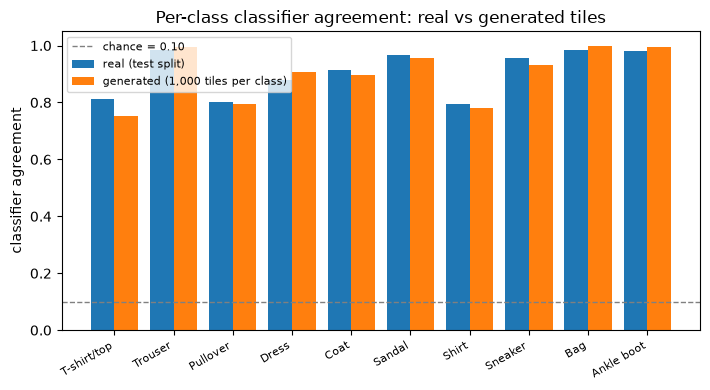

In [16]:
# Compare classifier agreement by class for real test images and generated images
xs = np.arange(N_CLASSES)
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.bar(xs - 0.2, real_per_class, width=0.4, label="real (test split)")
ax.bar(xs + 0.2, gen_per_class, width=0.4, label="generated (1,000 tiles per class)")
ax.axhline(0.10, color="gray", linestyle="--", linewidth=1, label="chance = 0.10")
ax.set_xticks(xs)
ax.set_xticklabels(CLASSES, rotation=30, ha="right", fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("classifier agreement")
ax.set_title("Per-class classifier agreement: real vs generated tiles")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "fig5-classifier-accuracy.png", dpi=110)
plt.show()


### Failure strip: 64 images from the weakest measured class (Figure 7)


failure strip: class 0 (T-shirt/top), 12 of 64 tiles classified as another class
  tile 56 (row 8, column 1) -> Shirt (confidence 1.00)
  tile 40 (row 6, column 1) -> Dress (confidence 0.98)
  tile 23 (row 3, column 8) -> Shirt (confidence 0.88)
  tile  7 (row 1, column 8) -> Shirt (confidence 0.87)
  tile 12 (row 2, column 5) -> Dress (confidence 0.83)


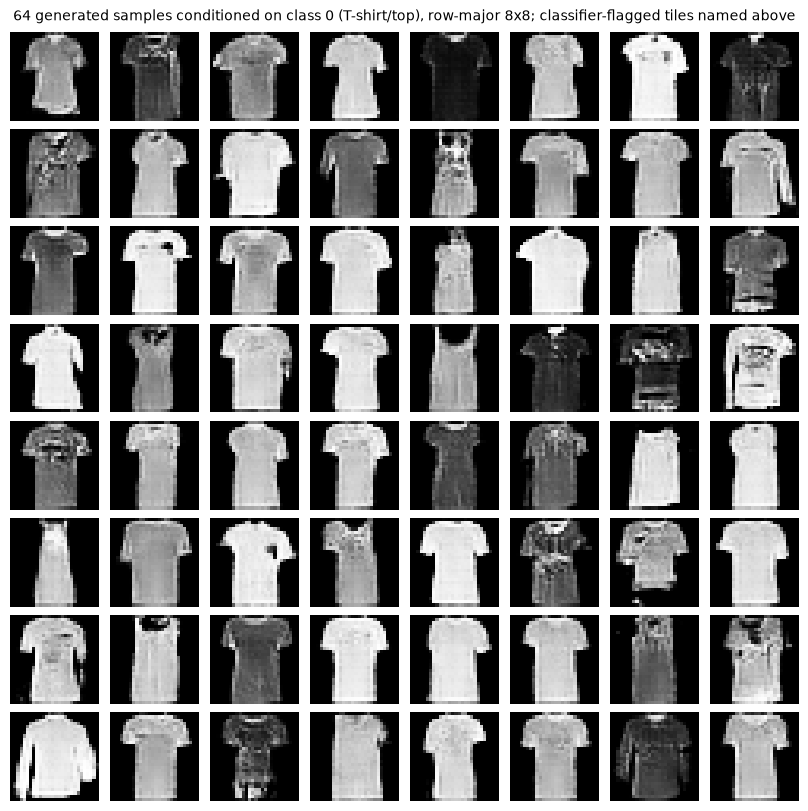

In [17]:
# Create a figure with 64 generated images from the weakest measured class, drawn from a
# balanced 640-image eval-mode set. Classifier-flagged tiles are named in the printout.
STRIP_CLASS = weakest
n_strip = 64
N_MIX = N_CLASSES * n_strip   # 640: exactly 64 tiles per class under cycling labels
torch.manual_seed(SEED + 2)   # strip seed, disclosed
mix_z = torch.randn(N_MIX, NZ, device=DEVICE)
mix_y = torch.arange(N_MIX, device=DEVICE) % N_CLASSES
mix_imgs = torch.empty(N_MIX, 1, 28, 28)
with torch.no_grad():
    for i in range(0, N_MIX, BATCH_SIZE):
        sl = slice(i, min(i + BATCH_SIZE, N_MIX))
        mix_imgs[sl] = G(mix_z[sl], mix_y[sl]).detach().cpu()
mix_labels = mix_y.cpu()
sel = (mix_labels == STRIP_CLASS).nonzero(as_tuple=True)[0][:n_strip]  # cyclic order
strip = mix_imgs[sel]
with torch.no_grad():
    strip_logits = clf(strip.to(DEVICE)).cpu()
strip_preds = strip_logits.argmax(1)
strip_probs = torch.softmax(strip_logits, dim=1)
wrong_idx = [i for i in range(n_strip) if int(strip_preds[i]) != STRIP_CLASS]
wrong_conf = [float(strip_probs[i, int(strip_preds[i])]) for i in wrong_idx]
print(f"failure strip: class {STRIP_CLASS} ({CLASSES[STRIP_CLASS]}), {len(wrong_idx)} of {n_strip} tiles classified as another class")
for i, conf in sorted(zip(wrong_idx, wrong_conf), key=lambda t: -t[1])[:5]:
    print(f"  tile {i:2d} (row {i // 8 + 1}, column {i % 8 + 1}) -> {CLASSES[int(strip_preds[i])]} (confidence {conf:.2f})")

strip = strip.reshape(8, 8, 1, 28, 28)
fig, axes = plt.subplots(8, 8, figsize=(8, 8), layout="constrained")
for r in range(8):
    for c in range(8):
        axes[r, c].imshow((strip[r, c, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
fig.suptitle(f"64 generated samples conditioned on class {STRIP_CLASS} ({CLASSES[STRIP_CLASS]}), row-major 8x8; classifier-flagged tiles named above", fontsize=10)
fig.savefig(FIGDIR / "fig6-failure-strip.png", dpi=110, bbox_inches="tight")
plt.show()


### Failure strip result (Figure 7)

Figure 7 shows `64` generated images from T-shirt/top, the class with the weakest measured class-agreement score (`0.75`). The classifier predicts a different class for `12` of the `64` images. The most confident incorrect prediction is at row 8, column 1, which the classifier reads as Shirt with confidence `1.00`.

A flagged image may indicate an error by the generator or by the classifier. The incorrect predictions match the weakest-class analysis above: Shirt is the most common incorrect prediction, followed by Dress (`0.04`) and Pullover (`0.03`). Figures 4 and 5 provide further visual evidence.


### Seed sensitivity

Two further runs with seeds `43` and `44` use the same configuration, with every random source re-seeded. The measured macro agreements were `0.9008` for seed `42`, `0.9020` for seed `43`, and `0.8843` for seed `44`, a spread of `0.0177`. The headline measurements are not an artifact of the disclosed seed. The adopted results remain those of seed `42`.


In [18]:
# Seed sensitivity: two further 50-epoch runs with fresh seeds 43 and 44, re-seeding every random
# source with the same configuration. The seed-42 models stay untouched.
def train_gan(seed, real_target, fake_target, log):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    g = Generator().to(DEVICE)
    d = Discriminator().to(DEVICE)
    opt_g = optim.Adam(g.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = optim.Adam(d.parameters(), lr=LR, betas=(0.5, 0.999))
    for epoch in range(1, EPOCHS + 1):
        ep_d, ep_g = [], []
        for imgs, labels in train_loader:
            imgs = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            bs = imgs.size(0)
            opt_d.zero_grad()
            loss_real = criterion(d(imgs, labels), torch.full((bs, 1), real_target, device=DEVICE))
            with torch.no_grad():
                fake_imgs = g(torch.randn(bs, NZ, device=DEVICE), labels)
            d_fake = d(fake_imgs, labels)
            loss_fake = criterion(d_fake, torch.full((bs, 1), fake_target, device=DEVICE))
            (loss_real + loss_fake).backward()
            opt_d.step()
            opt_g.zero_grad()
            g_loss = criterion(d(g(torch.randn(bs, NZ, device=DEVICE), labels), labels), torch.ones(bs, 1, device=DEVICE))
            g_loss.backward()
            opt_g.step()
            ep_d.append(float((loss_real + loss_fake).detach()))
            ep_g.append(float(g_loss.detach()))
        if log:
            print(f"  sensitivity seed {seed} epoch {epoch:2d}  D {np.mean(ep_d):.3f}  G {np.mean(ep_g):.3f}")
    return g, float(np.mean(ep_d)), float(np.mean(ep_g))

def eval_protocol(g):
    # 1,000 tiles per class under the adopted eval-mode protocol, disclosed seed
    g.eval()
    torch.manual_seed(SEED + 1)
    z = torch.randn(N_EVAL, NZ, device=DEVICE)
    y = torch.arange(N_EVAL, device=DEVICE) % N_CLASSES
    tiles = torch.empty(N_EVAL, 1, 28, 28)
    with torch.no_grad():
        for i in range(0, N_EVAL, 512):
            tiles[i:i + 512] = g(z[i:i + 512], y[i:i + 512]).cpu()
    y_cpu = y.cpu()
    preds = clf(tiles.to(DEVICE)).argmax(1).cpu()
    acc = float(np.mean([(preds[y_cpu == c] == c).float().mean() for c in range(N_CLASSES)]))
    feats = torch.cat([penult_features(tiles[i:i + 512].to(DEVICE)).cpu()
                       for i in range(0, N_EVAL, 512)])
    return acc, feats

print("seed sensitivity (same configuration; agreement on 1,000 tiles per class):")
print(f"  seed 42: final D {d_losses[-1]:.3f}, final G {g_losses[-1]:.3f}, macro agreement {macro_gen:.4f}")
sens = {}
for seed in (43, 44):
    g_s, d_fin, g_fin = train_gan(seed, REAL_TARGET, FAKE_TARGET, log=True)
    acc_s, _ = eval_protocol(g_s)
    sens[seed] = (d_fin, g_fin, acc_s)
    print(f"  seed {seed}: final D {d_fin:.3f}, final G {g_fin:.3f}, macro agreement {acc_s:.4f}")


seed sensitivity (same configuration; agreement on 1,000 tiles per class):
  seed 42: final D 1.390, final G 0.723, macro agreement 0.9008


  sensitivity seed 43 epoch  1  D 1.138  G 1.156


  sensitivity seed 43 epoch  2  D 1.106  G 1.224


  sensitivity seed 43 epoch  3  D 1.123  G 1.152


  sensitivity seed 43 epoch  4  D 1.194  G 1.017


  sensitivity seed 43 epoch  5  D 1.220  G 1.009


... (93 outputs left out)

  sensitivity seed 44 epoch 48  D 1.386  G 0.735


  sensitivity seed 44 epoch 49  D 1.386  G 0.735


  sensitivity seed 44 epoch 50  D 1.387  G 0.732


  seed 44: final D 1.387, final G 0.732, macro agreement 0.8843


### Label-smoothing ablation

One further run trains with the one-sided smoothing variant of Salimans et al. (2016) and the disclosed seed, with the same configuration otherwise. The one-sided variant reached a macro agreement of `0.9100` and a feature distance of `16.1506`, against `0.9008` and `20.9619` for the adopted two-sided variant. The agreement difference of `0.0092` is within the variation of a single per-class comparison at this sample size. The one-sided variant measured better on both metrics and remains a possible training improvement.


In [19]:
# Label-smoothing ablation: the one-sided variant (real 0.9, generated 0.0)
# against the adopted two-sided variant (0.9 / 0.1), same seed and configuration.
g_one, d_one_fin, g_one_fin = train_gan(SEED, REAL_TARGET, 0.0, log=True)
acc_one, feats_one = eval_protocol(g_one)
d2_one = frechet_d2(real_feats, feats_one)
print("label-smoothing ablation (disclosed seed, same configuration except the smoothing targets):")
print(f"  two-sided (0.9 / 0.1): final D {d_losses[-1]:.3f}, final G {g_losses[-1]:.3f}, macro agreement {macro_gen:.4f}, feature distance {d2_gen:.4f}")
print(f"  one-sided (0.9 / 0.0): final D {d_one_fin:.3f}, final G {g_one_fin:.3f}, macro agreement {acc_one:.4f}, feature distance {d2_one:.4f}")


  sensitivity seed 42 epoch  1  D 0.682  G 3.232


  sensitivity seed 42 epoch  2  D 0.926  G 1.636


  sensitivity seed 42 epoch  3  D 0.919  G 1.623


  sensitivity seed 42 epoch  4  D 1.023  G 1.462


  sensitivity seed 42 epoch  5  D 1.119  G 1.279


  sensitivity seed 42 epoch  6  D 1.183  G 1.135


... (41 outputs left out)

  sensitivity seed 42 epoch 48  D 1.365  G 0.870


  sensitivity seed 42 epoch 49  D 1.367  G 0.866


  sensitivity seed 42 epoch 50  D 1.364  G 0.865


label-smoothing ablation (disclosed seed, same configuration except the smoothing targets):
  two-sided (0.9 / 0.1): final D 1.390, final G 0.723, macro agreement 0.9008, feature distance 20.9619
  one-sided (0.9 / 0.0): final D 1.364, final G 0.865, macro agreement 0.9100, feature distance 16.1506


### Reproducible headline numbers


In [20]:
# Print the fixed headline numbers for a quick check after a fresh run.
print("recorded headline numbers")
print(f"epochs {EPOCHS}, batch {BATCH_SIZE}, seed {SEED}, device {DEVICE}")
print(f"D chance {D_CHANCE:.3f}, G chance {G_CHANCE:.3f}")
print(f"epoch-1 D {d_losses[0]:.3f}, final D {d_losses[-1]:.3f}")
print(f"epoch-1 G {g_losses[0]:.3f}, final G {g_losses[-1]:.3f}")
print(f"mean D real logits {np.mean(d_logits_real_m):.3f}, mean D fake logits {np.mean(d_logits_fake_m):.3f}")
print(f"training time {elapsed:.0f} s over {EPOCHS} epochs")
print(f"classifier: {EPOCHS_CLF} epochs, epoch-1 validation accuracy {acc_per_epoch[0]:.4f}, final real test accuracy {test_acc:.4f} (chance 0.10)")
print(f"macro generated-tile accuracy {macro_gen:.4f} vs macro real-test accuracy {macro_real:.4f} (real-vs-generated gap {macro_real - macro_gen:+.4f})")
print(f"measured weakest generated class {weakest} {CLASSES[weakest]} (generated {gen_per_class[weakest]:.2f} vs real-test {real_per_class[weakest]:.2f})")
print(f"generation protocol: eval mode adopted; eval-mode mixed macro {eval_mixed:.4f}, train-mode mixed macro {train_mixed:.4f}")
eval_comp = abs(max(eval_mixed, eval_single, eval_b1) - min(eval_mixed, eval_single, eval_b1))
train_comp = abs(max(train_mixed, train_single) - min(train_mixed, train_single))  # train batch-1: not measurable at n=1
print(f"protocol cross-composition spread (max - min): eval mode {eval_comp:.4f}, train mode {train_comp:.4f}")
print(f"generation protocol pixel-difference check: eval mode {eval_diff:.4f}, train mode {train_diff:.4f}")
print(f"feature-space Frechet distance: real test vs generated d^2 = {d2_gen:.4f} (real-vs-real comparison {d2_floor:.4f})")
print(f"intra-class diversity macro: generated {div_gen_macro:.4f} vs real {div_real_macro:.4f} (ratio {div_gen_macro / div_real_macro:.2f})")
print(f"failure strip: {len(wrong_idx)} of {n_strip} {CLASSES[STRIP_CLASS]}-conditioned tiles classified as another class")
if wrong_idx:
    i_best, c_best = max(zip(wrong_idx, wrong_conf), key=lambda t: t[1])
    print(f"strongest wrong-class tile: {i_best} (row {i_best // 8 + 1}, column {i_best % 8 + 1}) -> {CLASSES[int(strip_preds[i_best])]} (confidence {c_best:.2f})")
print(f"seed sensitivity: macro agreement seed 42 {macro_gen:.4f}, seed 43 {sens[43][2]:.4f}, seed 44 {sens[44][2]:.4f}")
print(f"label smoothing: two-sided agreement {macro_gen:.4f} vs one-sided {acc_one:.4f}; feature distance {d2_gen:.4f} vs {d2_one:.4f}")


recorded headline numbers
epochs 50, batch 128, seed 42, device cuda
D chance 1.386, G chance 0.693
epoch-1 D 0.814, final D 1.390
epoch-1 G 2.019, final G 0.723
mean D real logits 0.133, mean D fake logits -0.134
training time 444 s over 50 epochs
classifier: 10 epochs, epoch-1 validation accuracy 0.9019, final real test accuracy 0.9074 (chance 0.10)
macro generated-tile accuracy 0.9008 vs macro real-test accuracy 0.9074 (real-vs-generated gap +0.0066)
measured weakest generated class 0 T-shirt/top (generated 0.75 vs real-test 0.81)
generation protocol: eval mode adopted; eval-mode mixed macro 0.8980, train-mode mixed macro 0.8830
protocol cross-composition spread (max - min): eval mode 0.0000, train mode 0.7760
generation protocol pixel-difference check: eval mode 0.0000, train mode 1.9997
feature-space Frechet distance: real test vs generated d^2 = 20.9619 (real-vs-real comparison 1.3127)
intra-class diversity macro: generated 779.0601 vs real 896.4631 (ratio 0.87)
failure strip: 12

## How to run: environment and data

### Environment

The repository uses a `uv` virtual environment with Python `3.13` and the CUDA build of PyTorch. The `+cu128` package pins in `requirements.txt` cannot be resolved from plain PyPI. An installation that does not include the additional index fails on `torch==2.11.0+cu128`, and the same issue applies to torchvision. The `requirements.txt` pins were captured with `pip freeze`.

Use the following command to install the dependencies with the PyTorch package index:

```bash
uv pip install --python .venv --extra-index-url https://download.pytorch.org/whl/cu128 --index-strategy unsafe-best-match -r requirements.txt
```

The notebook also runs on CPU if no CUDA GPU is available, only slower.

### Data

The dataset files are stored in `data/FashionMNIST/raw/` at the repository root: about `55` MB uncompressed, `31` MB in compressed archives, `8` files.

The data loader uses `root="data"` and `download=False`, with `download=True` as the documented fallback. The hash-check cell verifies the four archives against the values in `DATASET.md`. That file also records the dataset provenance and license.

### Run order

Run the notebook from top to bottom, or execute it with `nbconvert`:

```bash
.venv\Scripts\python.exe -m nbconvert --to notebook --execute --inplace generative_model.ipynb
```

The full run trains four GANs for `50` epochs each: the disclosed run, two seed-sensitivity runs, and one label-smoothing ablation run. The classifier training cell (`10` epochs) evaluates the test split once at the end.


## References (notebook)

- Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B., & Hochreiter, S. (2017). GANs trained by a two time-scale update rule converge to a local Nash equilibrium. Advances in Neural Information Processing Systems, 30. https://papers.nips.cc/paper_files/paper/2017/hash/8a1d694707eb0fefe65871369074926d-Abstract.html
- Mirza, M., & Osindero, S. (2014). Conditional generative adversarial nets. arXiv. https://arxiv.org/abs/1411.1784
- Odena, A., Olah, C., & Shlens, J. (2017). Conditional image synthesis with auxiliary classifier GANs. Proceedings of the 34th International Conference on Machine Learning, PMLR 70. https://arxiv.org/abs/1610.09585
- Radford, A., Metz, L., & Chintala, S. (2016). Unsupervised representation learning with deep convolutional generative adversarial networks. arXiv. https://arxiv.org/abs/1511.06434
- Salimans, T., Goodfellow, I., Zaremba, W., Cheung, V., Radford, A., & Chen, X. (2016). Improved techniques for training GANs. Advances in Neural Information Processing Systems, 29. https://proceedings.neurips.cc/paper_files/paper/2016/hash/8a3363abe792db2d8761d6403605aeb7-Abstract.html
- Xiao, H., Rasul, K., & Vollgraf, R. (2017). Fashion-MNIST: A novel image dataset for benchmarking machine learning algorithms. arXiv. https://arxiv.org/abs/1708.07747

## Notebook summary

This notebook trained a conditional DCGAN on Fashion-MNIST for `50` epochs and evaluated the generated `28x28` garment images with a separately trained classifier. The class-agreement and feature-space measurements share this classifier's representation and its potential biases.

The adversarial losses approached their chance baselines (`1.390` against `1.386`, `0.723` against `0.693`). The classifier predicted the conditioning label for `0.9008` of generated images against `0.9074` on real test images.

The feature distance was `21.0` against a same-method reference of `1.3` (intra-class diversity ratio `0.87`). T-shirt/top, the weakest measured class at `0.75`, is examined with a failure strip.
